## **Load and Clean CSV Files**

### **Combine the CSV Files**

In [13]:
import sys
import os
sys.path.append(os.path.abspath('..'))

from quinex_application.scopus_data import ProcessScopusData
import glob

# csvs_paths = glob.glob("../data/external/scopus_query1/by_years/scopus_*.csv")
# output_path = "../data/external/scopus_query1/scopus_2025_04_30.csv"
# cleaned_output_path = "../data/external/scopus_query1/scopus_2025_04_30_cleaned.csv"
csvs_paths = glob.glob("../data/external/scopus_query2/by_years/scopus_*.csv")
output_path = "../data/external/scopus_query2/scopus_2025_05_08.csv"
cleaned_output_path = "../data/external/scopus_query2/scopus_2025_05_08_cleaned.csv"


scopus = ProcessScopusData(csvs_paths, output_path, cleaned_output_path)

In [14]:
df = scopus.combine_csvs()
print(len(df))

27130


### **Clean OpenAccess Column**

In [15]:
df = scopus.clean_openaccess()
print(len(df))

27130


### **Clean duplicate DOIs**

In [16]:
df = scopus.load_csv(cleaned=False)

In [17]:
duplicate_doi_values = df["DOI"].value_counts()
duplicate_doi_values = duplicate_doi_values[duplicate_doi_values > 1]
print(f"Anzahl verschiedener mehrfacher DOIs: {len(duplicate_doi_values)}")
print(f"Anzahl an Zeilen mit mehrfacher DOI: {duplicate_doi_values.sum()}")

Anzahl verschiedener mehrfacher DOIs: 30
Anzahl an Zeilen mit mehrfacher DOI: 60


In [18]:
df_cleaned = scopus.remove_duplicates_doi()
print(len(df_cleaned))

27100


### **Save cleaned data**

In [19]:
scopus.save_df()

## **Analyse Metadata**

In [20]:
from quinex_application.visualisation_metadata import VisualisationMetadata

visualisation = VisualisationMetadata(cleaned_output_path)
display(visualisation.df.head())
print(len(visualisation.df))

,Year,Source title,Cited by,DOI,Link,Open Access
0,1955,Journal of Inorganic and Nuclear Chemistry,3,10.1016/0022-1902(55)80065-6,https://www.scopus.com/inward/record.uri?eid=2-s2.0-50449121789&doi=10.1016%2f0022-1902%2855%2980065-6&partnerID=40&md5=2da0b49bc3ab506e92e5d009ee0cc158,Green Open Access
1,1962,Journal of the Atomic Energy Society of Japan / Atomic Energy Society of Japan,0,10.3327/jaesj.4.287,https://www.scopus.com/inward/record.uri?eid=2-s2.0-85007937695&doi=10.3327%2fjaesj.4.287&partnerID=40&md5=6e100a900cf04f2c6ce9d11fbab2eb42,Bronze Open Access
2,1966,Journal of Nuclear Science and Technology,3,10.1080/18811248.1966.9732377,https://www.scopus.com/inward/record.uri?eid=2-s2.0-84914958831&doi=10.1080%2f18811248.1966.9732377&partnerID=40&md5=bcaae4ba2629d80e5e69bf4308c08de9,Bronze Open Access
3,1967,Proceedings of the ASME Turbo Expo,0,10.1115/67-GT-37,https://www.scopus.com/inward/record.uri?eid=2-s2.0-84960894170&doi=10.1115%2f67-GT-37&partnerID=40&md5=643b7e27329f17a57133dc4a006c2fa4,Bronze Open Access
4,1967,Journal of the Atomic Energy Society of Japan / Atomic Energy Society of Japan,1,10.3327/jaesj.9.7,https://www.scopus.com/inward/record.uri?eid=2-s2.0-85007961619&doi=10.3327%2fjaesj.9.7&partnerID=40&md5=6572271988f6f77851f1c19d99db4e8e,Bronze Open Access


27100


### **Paper pro Jahr**

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_23124\73450831.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


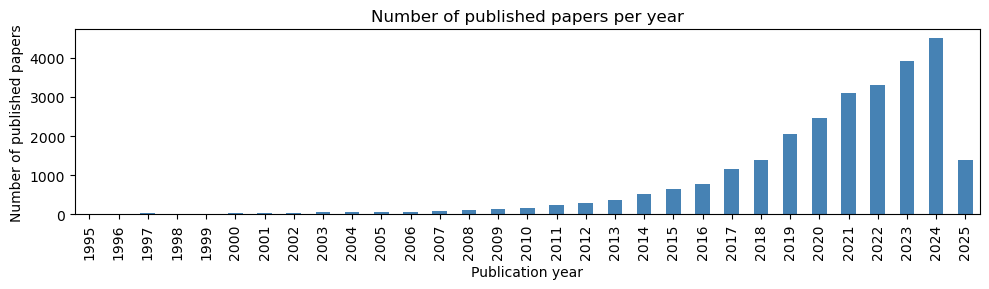

In [21]:
fig = visualisation.paper_per_year(start_year = 1995)
fig.show()

### **Zitierungen pro Jahr**

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_23124\2450258133.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


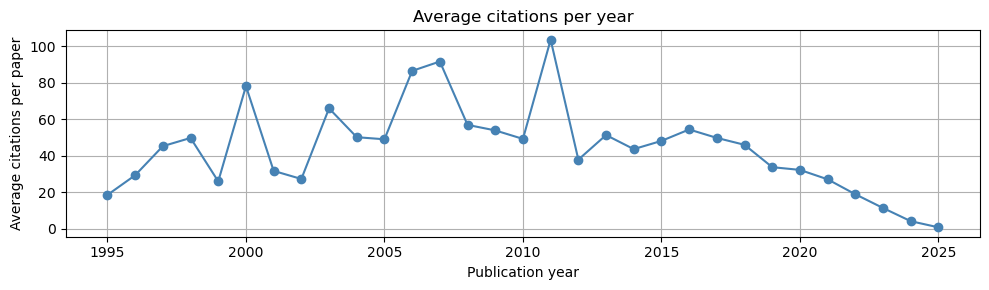

In [22]:
fig = visualisation.citations_per_year(start_year = 1995)
fig.show()

### **Journal**

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_23124\964440868.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


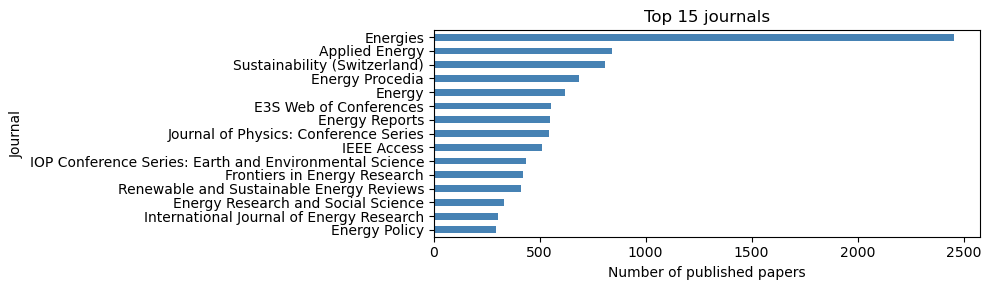

In [23]:
fig = visualisation.top_journals(number=15, by="count")
fig.show()

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_23124\2808972650.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


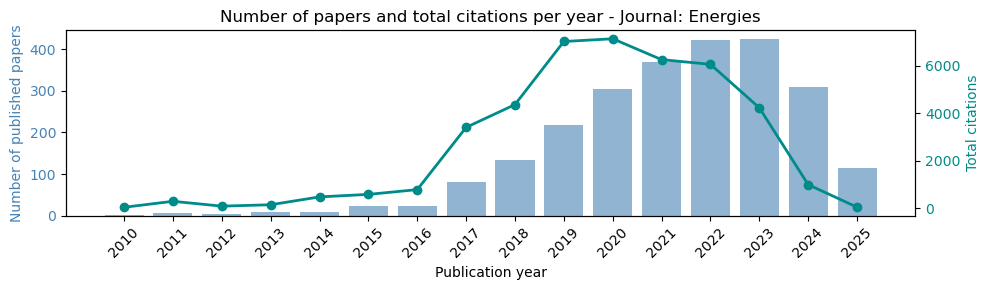

In [25]:
fig = visualisation.journal_trend("Energies")
fig.show()

### **Open Access**

In [ ]:
fig = visualisation.open_access()
fig.show()

In [ ]:
fig = visualisation.citations_open_access()
fig.show()

### **Top Paper**

In [ ]:
fig = visualisation.top_cited_papers(20, (12, 5))
fig.show()